In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/creditcard.csv')

# same two cleaning decisions as in 01_eda
df = df.drop_duplicates().reset_index(drop=True)
df['Hour'] = (df['Time'] // 3600) % 24

y = df['Class']
X = df.drop(columns=['Class', 'Time'])

print(X.shape, y.shape)

(283726, 30) (283726,)


In [2]:
train_test_split

<function sklearn.model_selection._split.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)>

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(y_train.mean(), y_test.mean())

0.0016653449643140364 0.0016741268107003137


In [4]:
from sklearn.preprocessing import RobustScaler

cols_to_scale = ['Amount', 'Hour']

scaler = RobustScaler()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale]  = scaler.transform(X_test[cols_to_scale])

print(X_train[cols_to_scale].describe().round(2))

          Amount       Hour
count  226980.00  226980.00
mean        0.92      -0.11
std         3.41       0.65
min        -0.31      -1.67
25%        -0.23      -0.56
50%         0.00       0.00
75%         0.77       0.44
max       272.10       0.89


In [5]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    class_weight=
    'balanced',
    max_iter=1000,
    random_state=42
)

logreg.fit(X_train, y_train)

print('done')

done


In [6]:
from sklearn.metrics import average_precision_score

y_proba = logreg.predict_proba(X_test)[:, 1]

auprc = average_precision_score(y_test, y_proba)

print('Baseline AUPRC:', round(auprc, 4))

Baseline AUPRC: 0.6731


In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=42
)

hgb.fit(X_train, y_train)

y_proba_hgb = hgb.predict_proba(X_test)[:, 1]

auprc_hgb = average_precision_score(y_test, y_proba_hgb)

print('HistGB AUPRC:', round(auprc_hgb, 4))

HistGB AUPRC: 0.716


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_lr = cross_val_score(
    logreg, X_train, y_train,
    cv=cv,
    scoring='average_precision'
)

scores_hgb = cross_val_score(
    hgb, X_train, y_train,
    cv=cv,
    scoring='average_precision'
)

print('LogReg:', scores_lr.round(4), '| mean:', scores_lr.mean().round(4), '| std:', scores_lr.std().round(4))
print('HistGB:', scores_hgb.round(4), '| mean:', scores_hgb.mean().round(4), '| std:', scores_hgb.std().round(4))

LogReg: [0.7731 0.7447 0.7108 0.7525 0.7908] | mean: 0.7544 | std: 0.0271
HistGB: [0.7635 0.7741 0.712  0.7509 0.752 ] | mean: 0.7505 | std: 0.0211


In [9]:
from sklearn.metrics import roc_auc_score

print('LogReg  — ROC AUC:', round(roc_auc_score(y_test, y_proba), 4),
      '| AUPRC:', round(average_precision_score(y_test, y_proba), 4))

print('HistGB  — ROC AUC:', round(roc_auc_score(y_test, y_proba_hgb), 4),
      '| AUPRC:', round(average_precision_score(y_test, y_proba_hgb), 4))

LogReg  — ROC AUC: 0.9655 | AUPRC: 0.6731
HistGB  — ROC AUC: 0.9553 | AUPRC: 0.716


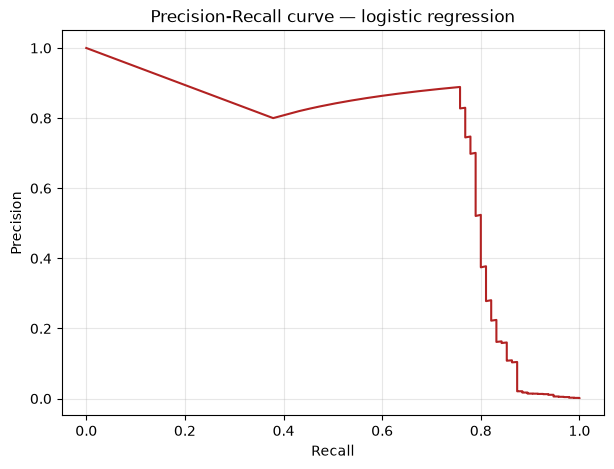

In [10]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color='firebrick')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve — logistic regression')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
import pandas as pd

rows = []

for t in [0.5, 0.9, 0.95, 0.99, 0.995, 0.999]:

    y_pred = (y_proba >= t).astype(int)

    tp = ((y_pred == 1) & (y_test == 1)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()

    rows.append({
        'threshold': t,
        'flagged': y_pred.sum(),
        'caught': tp,
        'false_alarms': fp,
        'missed': fn,
        'precision': round(tp / max(y_pred.sum(), 1), 3),
        'recall': round(tp / y_test.sum(), 3)
    })

print(pd.DataFrame(rows))

   threshold  flagged  caught  false_alarms  missed  precision  recall
0      0.500     1497      83          1414      12      0.055   0.874
1      0.900      278      78           200      17      0.281   0.821
2      0.950      188      76           112      19      0.404   0.800
3      0.990      120      75            45      20      0.625   0.789
4      0.995      107      75            32      20      0.701   0.789
5      0.999       98      73            25      22      0.745   0.768


In [12]:
amounts_test = df.loc[y_test.index, 'Amount']
avg_fraud_amount = amounts_test[y_test == 1].mean()

print('Average fraud amount:', round(avg_fraud_amount, 2))

COST_PER_REVIEW = 5

rows = []

for t in [0.5, 0.9, 0.95, 0.99, 0.995, 0.999]:

    y_pred = (y_proba >= t).astype(int)

    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()

    fraud_loss  = fn * avg_fraud_amount
    review_cost = fp * COST_PER_REVIEW

    rows.append({
        'threshold': t,
        'missed': fn,
        'false_alarms': fp,
        'fraud_loss': round(fraud_loss),
        'review_cost': round(review_cost),
        'total_cost': round(fraud_loss + review_cost)
    })

print(pd.DataFrame(rows))

Average fraud amount: 155.43
   threshold  missed  false_alarms  fraud_loss  review_cost  total_cost
0      0.500      12          1414        1865         7070        8935
1      0.900      17           200        2642         1000        3642
2      0.950      19           112        2953          560        3513
3      0.990      20            45        3109          225        3334
4      0.995      20            32        3109          160        3269
5      0.999      22            25        3420          125        3545


In [13]:
from sklearn.model_selection import cross_val_predict

proba_train_cv = cross_val_predict(
    logreg, X_train, y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

print(proba_train_cv.shape)
print('fraud rate:', round(y_train.mean(), 5))

(226980,)
fraud rate: 0.00167


Average fraud amount (train): 115.94
Best threshold: 0.965
Cost at that threshold: 7975


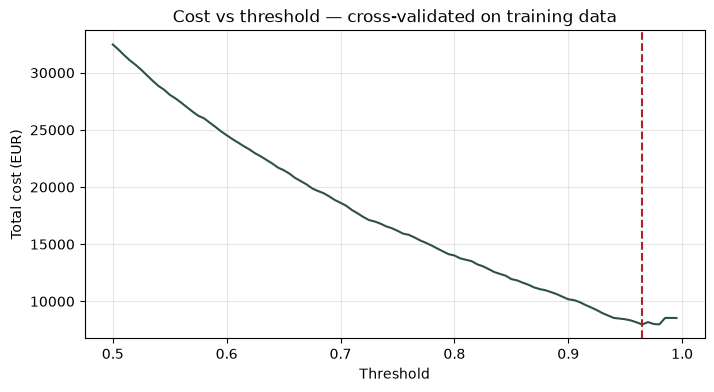

In [15]:
import numpy as np

amounts_train = df.loc[y_train.index, 'Amount']
avg_fraud_train = amounts_train[y_train == 1].mean()

print('Average fraud amount (train):', round(avg_fraud_train, 2))

COST_PER_REVIEW = 5

thresholds = np.arange(0.50, 1.00, 0.005)

costs = []

for t in thresholds:
    y_pred = (proba_train_cv >= t).astype(int)
    fp = ((y_pred == 1) & (y_train == 0)).sum()
    fn = ((y_pred == 0) & (y_train == 1)).sum()
    costs.append(fn * avg_fraud_train + fp * COST_PER_REVIEW)

costs = np.array(costs)

best_idx = costs.argmin()
best_threshold = thresholds[best_idx]

print('Best threshold:', round(best_threshold, 3))
print('Cost at that threshold:', round(costs[best_idx]))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs, color='darkslategray')
plt.axvline(best_threshold, color='firebrick', linestyle='--')
plt.xlabel('Threshold')
plt.ylabel('Total cost (EUR)')
plt.title('Cost vs threshold — cross-validated on training data')
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
y_pred_final = (y_proba >= best_threshold).astype(int)

tp = ((y_pred_final == 1) & (y_test == 1)).sum()
fp = ((y_pred_final == 1) & (y_test == 0)).sum()
fn = ((y_pred_final == 0) & (y_test == 1)).sum()

precision = tp / (tp + fp)
recall    = tp / (tp + fn)

print('Threshold:', round(best_threshold, 3))
print('Flagged:', y_pred_final.sum())
print('Caught:', tp, 'of', y_test.sum())
print('False alarms:', fp)
print('Missed:', fn)
print('Precision:', round(precision, 3))
print('Recall:', round(recall, 3))

Threshold: 0.965
Flagged: 155
Caught: 76 of 95
False alarms: 79
Missed: 19
Precision: 0.49
Recall: 0.8


In [17]:
cost_honest = fn * avg_fraud_amount + fp * COST_PER_REVIEW

print('Cost at honestly chosen threshold:', round(cost_honest))
print('Best possible in hindsight (Tuesday):', 3269)

Cost at honestly chosen threshold: 3348
Best possible in hindsight (Tuesday): 3269


In [19]:
fps, fns = [], []

for t in thresholds:
    y_pred = (proba_train_cv >= t).astype(int)
    fps.append(((y_pred == 1) & (y_train == 0)).sum())
    fns.append(((y_pred == 0) & (y_train == 1)).sum())

fps = np.array(fps)
fns = np.array(fns)

print('review cost  ->  best threshold')

for c in [1, 2, 5, 10, 20, 50]:

    costs_c = fns * avg_fraud_train + fps * c

    best_t = thresholds[costs_c.argmin()]

    print(f'{c:>6}  ->  {best_t:.3f}')

review cost  ->  best threshold
     1  ->  0.940
     2  ->  0.940
     5  ->  0.965
    10  ->  0.980
    20  ->  0.995
    50  ->  0.995
